# FFA school with OPALX

This needs to run the examples:: https://github.com/OPALX-project/OPALX/pull/663

Explore three scaling FFA rings: the original 16-cell ring at 12 MeV, its
55° spiral/D-off variant, and the fourfold ring at 3 MeV.

**OPALX computes the closed orbits and full linear tunes using native `COF`.**
Python (3.10 or later) writes inputs, runs OPALX, reads its output and plots the results. No
external orbit optimiser, PyNAFF or experimental probe recorder is needed.
The original `FFA25_OPAL.ipynb` and its old-OPAL helpers remain unchanged.

Use an OPALX build containing native scaling-FFA COF and full-tune reporting
(PR #663, commit `1300dd708` or later). This notebook uses only NumPy, pandas,
Matplotlib and h5py in addition to Jupyter. The OPALX Python environment is
`~/.venv-h6` on the teaching machine.

Before starting Jupyter, set `OPALX_EXE=/absolute/path/to/build/src/opalx`, or set
`EXECUTABLE` in the next cell. MPI launcher options are configurable through
`OPALX_MPI_FLAGS`; leave them empty for a normal local MPI installation. For
this machine's Open MPI setup use:

```sh
export OPALX_MPI_FLAGS='--host localhost:4 --map-by slot --bind-to none'
```

A full run launches three native COF solves, three short tracking experiments
on one rank. COF uses DOP853 and finite-difference ray traversals;
allow several minutes, particularly at 3 MeV. Each execution writes a fresh
session under `opalx/runs/`, preserving logs and inputs without reusing stale data.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from concurrent.futures import ThreadPoolExecutor
import os
import sys
import uuid

PROJECT = Path.cwd().resolve()
if not (PROJECT / "opalx" / "school.py").is_file():
    raise RuntimeError("Open this notebook from the FFA25-school directory.")
CACHE = PROJECT / "opalx" / "runs" / ".cache"
CACHE.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(CACHE / "matplotlib"))
os.environ.setdefault("XDG_CACHE_HOME", str(CACHE))
sys.path.insert(0, str(PROJECT / "opalx"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, FileLink
import school

%matplotlib inline
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 110, "savefig.dpi": 180})

EXECUTABLE = None  # Or "/absolute/path/to/build/src/opalx"; otherwise OPALX_EXE/PATH.
EXE = school.find_executable(EXECUTABLE)
SESSION = PROJECT / "opalx" / "runs" / (
    datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "-" + uuid.uuid4().hex[:8])
SESSION.mkdir(parents=True, exist_ok=False)

COF_DT = 1e-10          # Seconds; DOP853 for native orbit and linear optics.
COF_FDSTEP = 1e-6       # Metres; momentum steps are scaled by total p/(mc).
GUESS_OFFSET = (0., 0., 0., 0.)  # Add (x [m], px/mc, y [m], py/mc).
TRACK_DT = 5e-11       # Seconds; ordinary production Boris tracking.
TRACK_TURNS = 3         # Exact directed turns; increase to 20 or 50 for longer plots.
DISPLACEMENT = 1e-3     # Metres, as in the original teaching exercise.
DUMP_EVERY = 20         # Accepted tracking-step interval for native HDF5 snapshots.
WORKERS = 3            # Independent one-rank cases; use 1 to run them sequentially.

print("OPALX:", EXE)
print("Single-rank launcher flags:", school.mpi_flags())
print("Fresh session:", SESSION.relative_to(PROJECT))

OPALX: /private/tmp/opalx-ffa-pr-build/src/opalx
Single-rank launcher flags: ['--host', 'localhost:4', '--map-by', 'slot', '--bind-to', 'none']
Fresh session: opalx/runs/20261103T155923Z-28023ef5


## Coordinates, energy and input conventions

OPALX uses **horizontal x–z** and **vertical y**. The common ring centre is
`(-R0, 0, 0)` and launch is on the positive radial axis; a launch radius `r`
therefore has `x = r - R0`, `z = 0`. Momenta are mechanical **p/(mc)**, not slopes.

`COF` holds the **total kinetic energy** fixed, including radial momentum. The
old notebook added radial momentum to a full tangential reference momentum,
which slightly increased the actual energy. We use exactly 12 or 3 MeV here.

The bundled `.in` inputs define native `REAL` constants, using the old input
writer's formulas. `E0` and `P_MASS` determine `P0`; `R0`, F/D starts, widths and
ends determine cell phases and poses. Coordinates are written as
`X=R0*(COS(angle)-1)`, `Z=R0*SIN(angle)`, `THETA=-angle`.

`school.lattice_text` selects the exercise's energy, radius, spiral and D
constant; OPALX evaluates the derived expressions. Changing a common parameter
updates all corresponding magnets. The inputs retain the historical sequential
`MAGNET_END` placement and Enge-centre translation, with explicit symmetry copies.
Native `COF_DT`, `COF_FDSTEP` and `TRACK_DT` remain separate numerical controls;
the old RF-based step budget is replaced by exact directed turns.

The supplied guesses start close to the known orbits. To observe native Newton
iterations, try `GUESS_OFFSET = (1e-3, 1e-4, 1e-4, 1e-5)` in a fresh session.
The four-dimensional solver includes vertical coordinates.

In [2]:
cases = school.CASES
parameters = pd.DataFrame([
    {"case": c.key, "energy_MeV": c.energy_MeV, "R0_m": c.r0,
     "superperiods": c.periods, "spiral_deg": np.degrees(c.spiral),
     "D_field": "off" if c.d_strength == 0 else "on"} for c in cases
])
display(parameters)

cof_paths = {c.key: school.prepare_cof(
    c, SESSION / c.key / "cof", dt=COF_DT, fd=COF_FDSTEP,
    guess_offset=GUESS_OFFSET) for c in cases}
print("Example native COF command:")
cof_text = (cof_paths[cases[0].key] / "school.in").read_text()
print("ORBIT: COF" + cof_text.split("ORBIT: COF", 1)[1].split(";", 1)[0] + ";")

,case,energy_MeV,R0_m,superperiods,spiral_deg,D_field
0,16-cell,12.0,4.42,16,45.005835,on
1,55deg-d-off,12.0,4.42,16,55.000000,off
2,fourfold,3.0,4.00,4,30.000000,on


Example native COF command:
ORBIT: COF, LINE=SCHOOL, BEAM=BEAM1, DT=COF_DT, TIMEINTEGRATOR="DOP853",
       MAXPATH=COF_MAXPATH, MAXSTEPS=COF_MAXSTEPS, X=COF_R_GUESS-R0, PX=COF_PR_GUESS, Y=COF_Y_GUESS, PY=COF_PY_GUESS,
       FDSTEP={COF_FDSTEP,COF_FDSTEP*BG,COF_FDSTEP,COF_FDSTEP*BG},
       SCALES={POSITION_SCALE,BG,POSITION_SCALE,BG}, XTOL=COF_XTOL, PTOL=COF_PTOL, MAXIT=COF_MAXIT, OUTPUT="orbit.json";


## Native closed orbits and full tunes

Each case runs in its own directory. `run.log` preserves native stdout;
`orbit.json` is the result of this fresh solve. A failed process, missing full
tunes, unstable numerical matrix or incomplete orbit closes the workflow with
an explicit error instead of substituting data.

COF's matrix eigenanalysis reports fractional modes. Its additional continuous
phase traversal determines the oriented branch and integer winding for these
stable, uncoupled planar rings. The following **full tunes are native output**.
They are infinitesimal-amplitude linear tunes, not frequencies fitted to the
1 mm trajectories plotted later.

In [3]:
def solve_case(case):
    path = cof_paths[case.key]
    school.execute(path, EXE)
    return case.key, school.read_cof(case, path)

with ThreadPoolExecutor(max_workers=WORKERS) as pool:
    cof_results = dict(pool.map(solve_case, cases))

for case in cases:
    print("\n" + case.label)
    print(school.native_report(cof_paths[case.key]))
summary = school.results_table([(case, cof_results[case.key]) for case in cases])
display(summary.style.format({"radius_m": "{:.10f}", "pr_mc": "{:.10f}",
                              "Qr": "{:.9f}", "Qy": "{:.9f}",
                              "max_position_residual_m": "{:.2e}"}))
summary.to_csv(SESSION / "native-cof-summary.csv", index=False)

Running cof on 1 rank(s); log: /Users/adelmann/git/FFA25-school/opalx/runs/20261103T155923Z-28023ef5/16-cell/cof/run.log


Running cof on 1 rank(s); log: /Users/adelmann/git/FFA25-school/opalx/runs/20261103T155923Z-28023ef5/fourfold/cof/run.log
Running cof on 1 rank(s); log: /Users/adelmann/git/FFA25-school/opalx/runs/20261103T155923Z-28023ef5/55deg-d-off/cof/run.log



16 cells · original spiral
OPAL-X> Status=0 Closed orbit verified by a fresh map evaluation. evaluations=10
OPAL-X> Coordinates (x,px,y,py): -0.027074444530416741 0.016280388878730002 0 0 
OPAL-X> Residual: -2.7224750231980011e-14 5.5164206536062466e-16 0 0 
OPAL-X> One-turn eigenanalysis: STABLE (spectral test)
OPAL-X> Mode 1: fractional phase 0.3911121265614163, conjugate branch 0.6088878734385837
OPAL-X> Mode 2: fractional phase 0.4106604509149038, conjugate branch 0.5893395490850962
OPAL-X> Full tunes (uncoupled planar): horizontal/radial=3.4106604509149037 vertical=3.3911121265614161
OPAL-X> Phase samples=5903 maximum phase step_rad=0.005435145527349583

55° spiral · D off
OPAL-X> Status=0 Closed orbit verified by a fresh map evaluation. evaluations=10
OPAL-X> Coordinates (x,px,y,py): -0.25673629772097417 0.017567795069157881 0 0 
OPAL-X> Residual: 4.9960036108132044e-16 4.0453751459779141e-15 0 0 
OPAL-X> One-turn eigenanalysis: STABLE (spectral test)
OPAL-X> Mode 1: fractional 

,lattice,energy_MeV,radius_m,pr_mc,Qr,Qy,max_position_residual_m
0,16 cells · original spiral,12.000000,4.3929255555,0.0162803889,3.410660451,3.391112127,2.72e-14
1,55° spiral · D off,12.000000,4.1632637023,0.0175677951,3.117740021,1.189209858,5.00e-16
2,Fourfold ring · 3 MeV,3.000000,3.9849687589,0.0087047468,3.447385959,3.438847127,7.05e-13


Expected scale: the original ring has tunes near (3.41066, 3.39111), the
55°/D-off ring near (3.11774, 1.18921), and the fourfold ring near
(3.44739, 3.43885). These rounded values are orientation checks, not substituted
results. The original spiral argument is `3.142/4`, about 45.0058°, deliberately
preserved instead of silently replacing it by π/4.

**Exercise:** compare the launch radius and vertical tune when the D field is
switched off and the spiral increased. Explain why the fourfold superperiod's
phase advance above one half cannot be inferred from a real-signal FFT peak
alone.

If full tunes are withheld, inspect native stdout and refine DT/FDSTEP.
A large finite-difference stencil can falsely fail the unit-circle diagnostic;
do not relax its stability tolerance to obtain an answer.

## Native tracking, field maps and perturbations

Launch eight deterministic FROMFILE particles: a closed reference, opposite
radial and vertical offsets, an opposite combined pair, and a duplicate closed
reference. All receive the same full native closed-state momentum, so the
energy remains fixed. **BEAM PC is omitted for FROMFILE.** Space charge is off.

`RUN, TURNS=...` requests physical directed revolutions. Native HDF5 snapshots
replace the old `trackOrbit.dat` reader. Native `DUMPEMFIELDS` replaces legacy
`DUMPFIELDS`; cylindrical input angles are radians, while output angles are
degrees. Its vertical coordinate is Y and vertical field is By. The cylindrical
origin is shifted to the actual ring centre.

The HDF5 reader reconstructs laboratory positions/momenta from the moving
reference chart using stored RefPartR/RefPartP (planar rings), checks particle
IDs at every snapshot, preserving physical particle identity regardless of
HDF5 row ordering. No `.loss` file copying or stale probe files
are involved.

In [4]:
track_paths = {c.key: school.prepare_tracking(
    c, cof_results[c.key], SESSION / c.key / "track", turns=TRACK_TURNS,
    dt=TRACK_DT, displacement=DISPLACEMENT, dump_every=DUMP_EVERY, maps=True)
    for c in cases}

def track_case(case):
    path = track_paths[case.key]
    school.execute(path, EXE)
    return case.key, school.read_trajectories(case, path)

with ThreadPoolExecutor(max_workers=WORKERS) as pool:
    trajectories = dict(pool.map(track_case, cases))

diagnostics = pd.DataFrame([
    {"case": c.key, "snapshots": trajectories[c.key].frame.nunique(),
     "particles": trajectories[c.key].row.nunique(),
     "max_relative_momentum_norm_error": float(
         abs(trajectories[c.key].p_norm_mc - c.p0).max()/c.p0)} for c in cases
])
display(diagnostics)
assert (diagnostics.particles == 8).all()
assert (diagnostics.max_relative_momentum_norm_error < 1e-7).all()

Running track on 1 rank(s); log: /Users/adelmann/git/FFA25-school/opalx/runs/20261103T155923Z-28023ef5/16-cell/track/run.log
Running track on 1 rank(s); log: /Users/adelmann/git/FFA25-school/opalx/runs/20261103T155923Z-28023ef5/fourfold/track/run.log


Running track on 1 rank(s); log: /Users/adelmann/git/FFA25-school/opalx/runs/20261103T155923Z-28023ef5/55deg-d-off/track/run.log

,case,snapshots,particles,max_relative_momentum_norm_error
0,16-cell,4615,8,1.411974e-11
1,55deg-d-off,4555,8,1.095088e-11
2,fourfold,6996,8,2.590587e-11


## Original 16-cell ring, 12 MeV

The field maps below come from the native field evaluator. The black curve is
the tracked closed launch. The radius-versus-azimuth view makes the scalloping
visible without magnifying the full-ring plot.

The orbit line begins at the first recorded HDF5 snapshot; closure is checked
by native COF residuals, rather than by the gap between plotted endpoints.

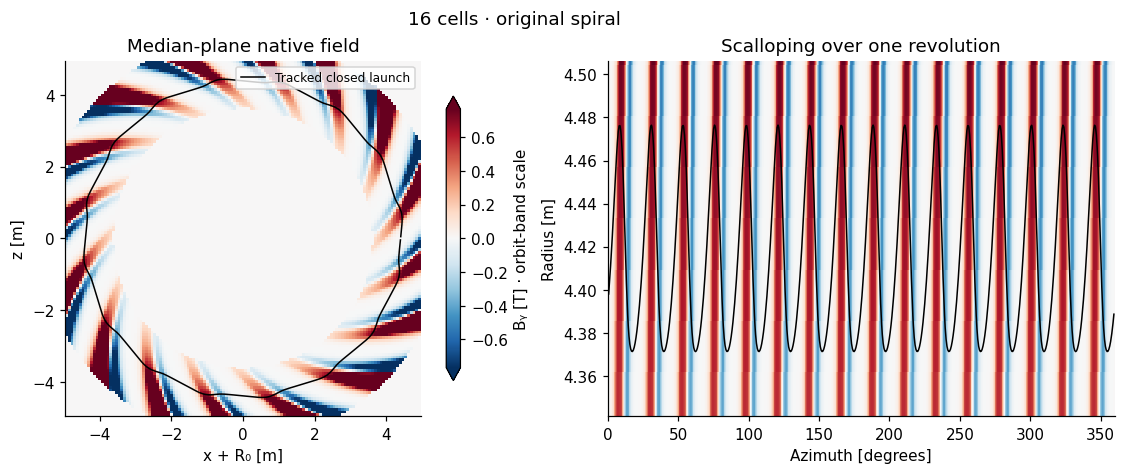

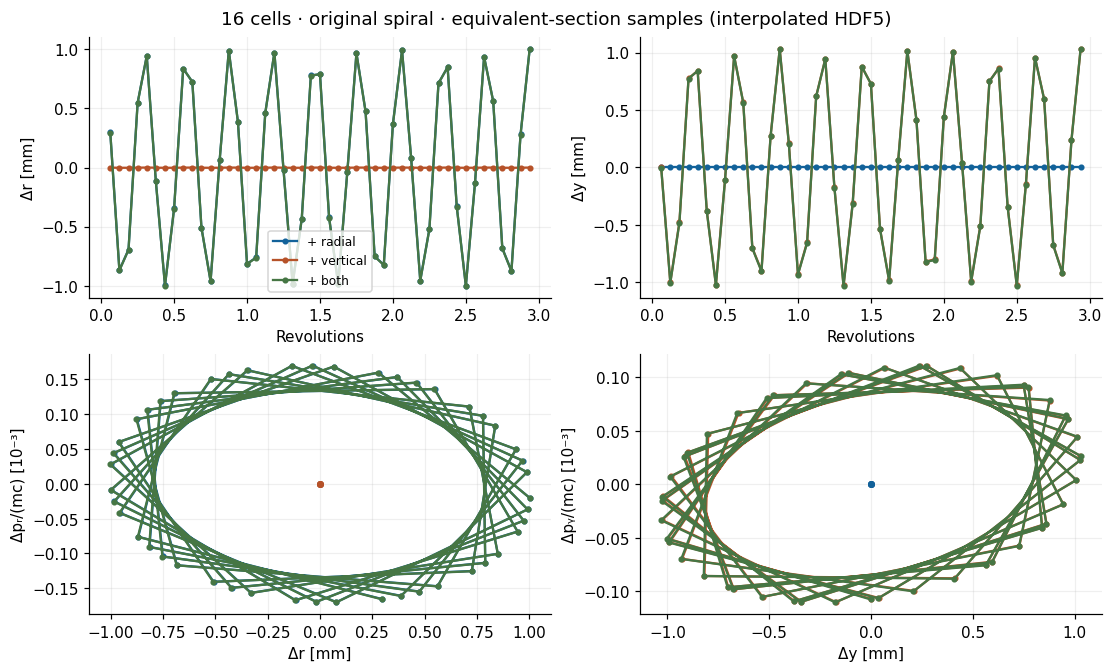

In [5]:
case = cases[0]
display(school.plot_fields_and_orbit(case, track_paths[case.key], trajectories[case.key]))
plt.close("all")
display(school.plot_oscillations(case, track_paths[case.key], trajectories[case.key]))
plt.close("all")

The phase plots sample equivalent superperiod sections by interpolating HDF5
snapshots and subtracting the tracked reference at the same section. Their
resolution depends on `DUMP_EVERY`; they illustrate motion and are **not** used
to compute the reported native tunes. More turns give denser portraits.
Finite-amplitude tunes can differ from the linear COF values.

**Exercise:** halve the displacement, then increase the number of turns. Which
features change, and which linear COF predictions should remain unchanged?

The combined-offset curve nearly overlaps the pure radial/vertical responses
for these small, approximately decoupled oscillations. A pure offset in the
other plane gives the near-zero curve.

## Change the spiral to 55° and switch D off

The F strengths, Enge profiles and nominal geometry remain the same. D has
zero field while retaining its nominal arc, preserving ring closure. Compare
both the orbit radius and the vertical oscillations with the original ring.

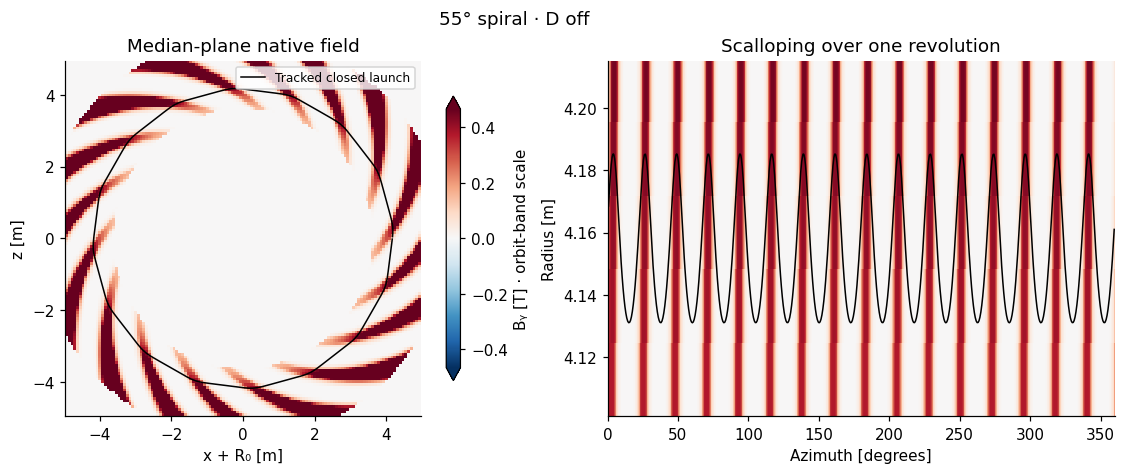

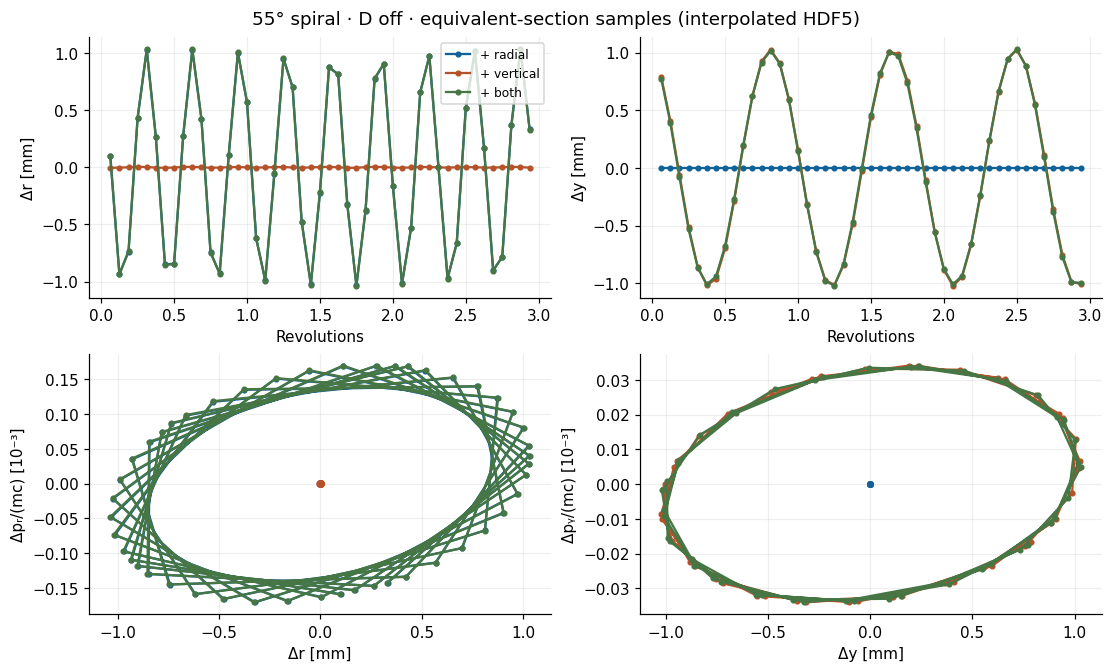

In [6]:
case = cases[1]
display(school.plot_fields_and_orbit(case, track_paths[case.key], trajectories[case.key]))
plt.close("all")
display(school.plot_oscillations(case, track_paths[case.key], trajectories[case.key]))
plt.close("all")

## Fourfold ring, 3 MeV

Each 90° superperiod contains four different F/D pairs, including unequal gaps.
The field index is 7.4319 and spiral angle 30°. It is not a ring of sixteen
identical optical cells: use four superperiods when interpreting phase advance.
Native COF counts the full phase winding without needing that symmetry as input.

Four section samples per revolution make a full tune near 3.44 appear near
0.55–0.56 oscillations per turn in these stroboscopic plots. Native COF resolves
the full phase winding; do not read the full tune from the slow plotted wave.

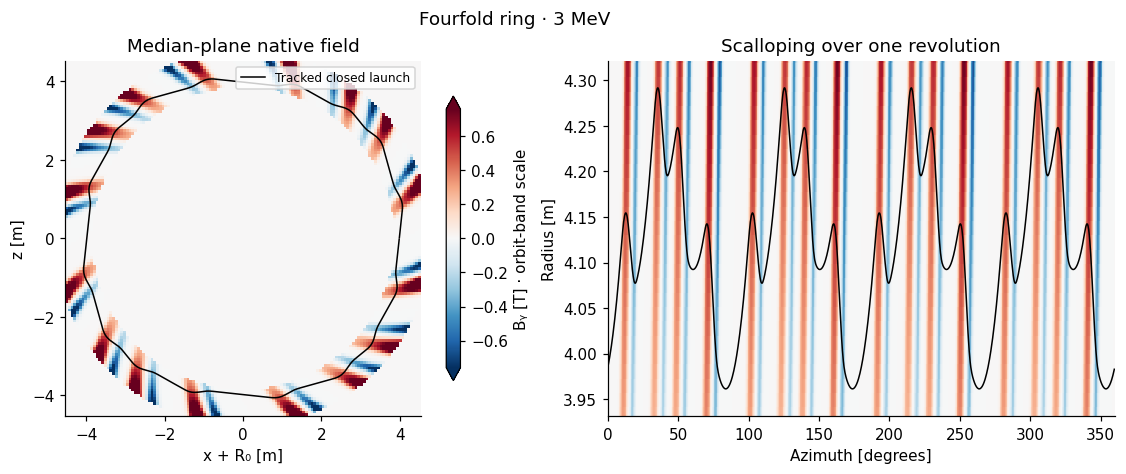

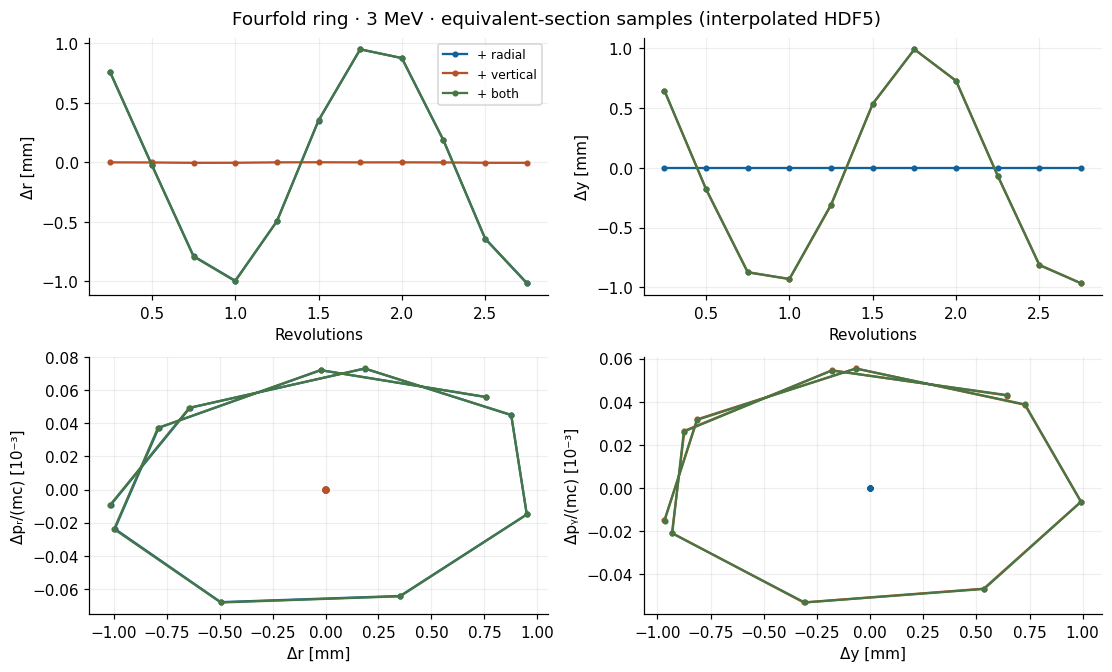

In [7]:
case = cases[2]
display(school.plot_fields_and_orbit(case, track_paths[case.key], trajectories[case.key]))
plt.close("all")
display(school.plot_oscillations(case, track_paths[case.key], trajectories[case.key]))
plt.close("all")

## Numerical checks and next experiments

- Change `GUESS_OFFSET` to test native four-dimensional Newton convergence.
- Halve `COF_DT` and `COF_FDSTEP` separately; compare full tunes and residuals.
  Closure alone is not an integration-accuracy guarantee.
- Halve `TRACK_DT` and `DUMP_EVERY` separately to distinguish transport error
  from interpolation error in the plots.
- Use 20 or 50 exact turns to explore finite-amplitude motion. COF's linear
  tunes do not replace a separate nonlinear frequency/amplitude study.

The earlier validation establishes these three static, uncoupled planar rings.
The production-tracking tune-convergence investigation remains open. A
controlled old-OPAL equivalence baseline, collective effects and GPU behavior
are outside this notebook's validation.

All generated inputs, native JSON, logs, HDF5 files, CSV and figures are local
to the fresh session. The original notebook and its helpers are preserved.

In [8]:
print("Native COF results:")
display(summary)
print("Outputs:", SESSION.relative_to(PROJECT))
for case in cases:
    display(FileLink(str((cof_paths[case.key] / "school.in").relative_to(PROJECT))))
    display(FileLink(str((track_paths[case.key] / "fields-and-orbit.pdf").relative_to(PROJECT))))

Native COF results:


,lattice,energy_MeV,radius_m,pr_mc,Qr,Qy,max_position_residual_m
0,16 cells · original spiral,12.0,4.392926,0.016280,3.410660,3.391112,2.722475e-14
1,55° spiral · D off,12.0,4.163264,0.017568,3.117740,1.189210,4.996004e-16
2,Fourfold ring · 3 MeV,3.0,3.984969,0.008705,3.447386,3.438847,7.045354e-13


Outputs: opalx/runs/20261103T155923Z-28023ef5


/Users/adelmann/git/FFA25-school/opalx/runs/20261103T155923Z-28023ef5/16-cell/cof/school.in

/Users/adelmann/git/FFA25-school/opalx/runs/20261103T155923Z-28023ef5/16-cell/track/fields-and-orbit.pdf

/Users/adelmann/git/FFA25-school/opalx/runs/20261103T155923Z-28023ef5/55deg-d-off/cof/school.in

/Users/adelmann/git/FFA25-school/opalx/runs/20261103T155923Z-28023ef5/55deg-d-off/track/fields-and-orbit.pdf

/Users/adelmann/git/FFA25-school/opalx/runs/20261103T155923Z-28023ef5/fourfold/cof/school.in

/Users/adelmann/git/FFA25-school/opalx/runs/20261103T155923Z-28023ef5/fourfold/track/fields-and-orbit.pdf